# **Imports**

In [10]:
import os
from dotenv import load_dotenv

In [11]:
from langchain.chat_models import init_chat_model
from langgraph.graph import StateGraph,START,END
from langchain_core.prompts import ChatPromptTemplate
from langchain_tavily import TavilySearch
import requests
from langchain_core.tools import tool
import getpass
from langgraph.prebuilt import ToolNode,tools_condition,create_react_agent
from IPython.display import Image,display
from langchain_groq import ChatGroq
from langgraph_supervisor import create_supervisor

In [12]:
from typing import TypedDict,List, Annotated
from operator import add
from langchain_core.messages import AnyMessage

In [13]:
import joblib

# **Initialization**

In [14]:
load_dotenv(override=True)


llm = init_chat_model(
    model="openai/gpt-oss-20b", 
    model_provider="openai",
    base_url="https://api.groq.com/openai/v1",
    api_key=os.environ.get("GROQ_API_KEY") 
)

llm.invoke("hello").content

'Hello! 👋 How can I help you today?'

# **Graph State**

In [15]:
from pydantic import BaseModel, Field

class struc(BaseModel):
    Email_Text : str = Field(...,description="Contains  the email which has: sender's name, subject, body including url")
    
struct_llm = llm.with_structured_output(struc)

#testing
text = 'here is an email: Brittany Moore ycarlson@yahoo.com DocuSign: Right-sized maximized moderator Dear Customer,  Team activity result race Mr environment political. Please verify your account by clicking here: http://moore-smith.com/  Regards, Brittany Moore'
struct_llm.invoke(text).Email_Text

'Brittany Moore <ycarlson@yahoo.com>\nSubject: DocuSign: Right-sized maximized moderator\n\nDear Customer,\nTeam activity result race Mr environment political.\nPlease verify your account by clicking here: http://moore-smith.com/\nRegards,\nBrittany Moore'

## *Phishing Tool*

In [16]:
from pathlib import Path

project_root = Path.cwd().parent if Path.cwd().name == "Notebooks" else Path.cwd()
model_dir = project_root / "Phishing_XGBoost_Model"

vectorizer = joblib.load(model_dir / "tfidf_Vectorizer.joblib")
model = joblib.load(model_dir / "XGBoost_Phishing_Model.joblib")

In [17]:
@tool
def Phishing_Detector(text: str = '') -> dict:
    '''
    Use this tool to identify if a email is Phising Email or not, and 
    using the toolmessage, explain why it is Phising or ordinary Email,
    make sure you will pass sender name,subject,body of the email and other
    given information
    '''
    Email_text =  struct_llm.invoke(text).Email_Text
    email = vectorizer.transform([Email_text])
    prob = model.predict_proba(email)[0,1]
        
    is_phishing = bool(prob >= 0.80)
    
    return {
        "is_phishing": is_phishing,
        "confidence": round(float(prob), 4),
        "recommendation": "Block and alert user" if is_phishing else "Allow to inbox"
    }

In [19]:
toolkit = [Phishing_Detector]
llm_tools = llm.bind_tools(toolkit)
llm_tools

_ChatModelBinding(bound=ChatOpenAI(metadata={'lc_versions': {'langchain-core': '1.6.0', 'langchain': '1.3.17', 'langchain-openai': '1.6.0'}}, client=<openai.resources.chat.completions.completions.Completions object at 0x000002A721216870>, async_client=<openai.resources.chat.completions.completions.AsyncCompletions object at 0x000002A7218D7BC0>, root_client=<openai.OpenAI object at 0x000002A721793170>, root_async_client=<openai.AsyncOpenAI object at 0x000002A7236E43B0>, model_name='openai/gpt-oss-20b', model_kwargs={}, openai_api_key=SecretStr('**********'), openai_api_base='https://api.groq.com/openai/v1', stream_chunk_timeout=120.0), kwargs={'tools': [{'type': 'function', 'function': {'name': 'Phishing_Detector', 'description': 'Use this tool to identify if a email is Phising Email or not, and \nusing the toolmessage, explain why it is Phising or ordinary Email,\nmake sure you will pass sender name,subject,body of the email and other\ngiven information', 'parameters': {'properties': {

## *Graph State*

In [20]:
from typing import TypedDict,List

class graph_state(TypedDict):
    email : str
    messages : List
    
    

In [21]:
def llm_node(state:graph_state) -> graph_state:
    messg = state['messages']
    
    prompt = ChatPromptTemplate.from_messages([
        ('System','You are a helpfull ai assistant who *ONLY USES* tools to find if email is phishing or not'),
        ('user','{input}')
    ])
    
    chain = prompt | llm_tools
    res = chain.invoke({'input':messg})
    
    state['messages'] = state['messages'] + [res]
    return state

In [22]:
tool_node = ToolNode(toolkit)

In [23]:
def tool_cond(state:graph_state)->str:
    last_message = state['messages'][-1]
    
    if last_message.tool_calls:
        return 'tools'
    else:
        return 'End'

## *the graph*

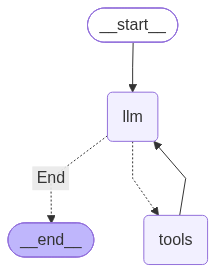

In [24]:
from langgraph.graph import StateGraph,START,END

graph = StateGraph(graph_state)

#creating nodes
graph.add_node('llm',llm_node)
graph.add_node('tools',tool_node)

#creating edges
graph.add_edge(START,'llm')
graph.add_conditional_edges('llm',tool_cond,{'tools':'tools','End':END})
graph.add_edge('tools','llm')
graph.add_edge('llm',END)

mdl = graph.compile()

Image(mdl.get_graph().draw_mermaid_png())

## *input*

In [25]:
from langchain_core.messages import HumanMessage
while True:
    ip = input("(type exit or quit or q to exit)\n(User): ")
    if ip in 'exitquit':
        break
    if not ip:
        break
    k_ip = HumanMessage(content=ip)
    result = mdl.invoke({'messages':[k_ip]})["messages"][-1].content
    print(result)

ValueError: Unexpected message type: System. Use one of 'human', 'user', 'ai', 'assistant', or 'system'.